# Predicted and unpredicted words

This notebook scores the GPT-2 XL encoding model from `code/prediction.py` separately on words that GPT-2 XL predicted and words it did not, for sub-03. A word counts as predicted when GPT-2 XL's top guess for its first token was the actual token. We match the two groups on word frequency and spoken duration, subsample them to equal size 200 times, and compare their encoding performance across lags and across electrodes.

Run `make prediction` before this notebook.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nilearn import datasets
from nilearn.plotting import plot_markers
from statsmodels.stats.multitest import multipletests

from utils import load_results, get_coord_atlas_labels, generate_null_dist, calculate_pvalues

plt.style.use("figures.mplstyle")
Path("../figures/prediction").mkdir(parents=True, exist_ok=True)

## Loading results

The result file holds the encoding performance on all held-out words for each fold, and the performance on the matched predicted and unpredicted words for each subsampling iteration, averaged over the two folds. It also keeps the word frequency, duration, and group of every word.

In [2]:
result_file = "../results/sub-03/prediction/sub-03_task-podcast_desc-gpt2.xl.l24_result.h5"

with h5py.File(result_file, "r") as f:
    for key in f.keys():
        print(f"{key} has a shape of: {f[key].shape}")
    scores = f["scores"][...]  # folds x electrodes x lags
    scores_pred = f["scores_pred"][...]  # iterations x electrodes x lags
    scores_unpred = f["scores_unpred"][...]
    balance = f["balance"][...]  # iterations x groups x (zipf, duration)
    n_matched = f["n_matched"][...]
    predicted = f["predicted"][...]
    zipf = f["zipf"][...]
    duration = f["duration"][...]
    lags = f["lags"][...]
    coords = f["coords"][...]
    ch_names = f["ch_names"][...].astype(str)

balance has a shape of: (200, 2, 2)
ch_names has a shape of: (235,)
coords has a shape of: (235, 3)
duration has a shape of: (5130,)
lags has a shape of: (128,)
n_matched has a shape of: (2,)
predicted has a shape of: (5130,)
scores has a shape of: (2, 235, 128)
scores_pred has a shape of: (200, 235, 128)
scores_unpred has a shape of: (200, 235, 128)
zipf has a shape of: (5130,)


## Word groups

Predicted words tend to be more frequent and shorter than unpredicted words, so we match the groups on both before comparing them. The table shows the two groups before matching and, averaged over iterations, after matching.

In [3]:
after = balance.mean(0)  # groups x (zipf, duration)

groups = pd.DataFrame(
    {
        ("before", "words"): [predicted.sum(), (~predicted).sum()],
        ("before", "mean Zipf"): [zipf[predicted].mean(), zipf[~predicted].mean()],
        ("before", "mean duration (s)"): [duration[predicted].mean(), duration[~predicted].mean()],
        ("after", "words"): [n_matched.sum(), n_matched.sum()],
        ("after", "mean Zipf"): after[:, 0],
        ("after", "mean duration (s)"): after[:, 1],
    },
    index=["predicted", "unpredicted"],
)

print(f"Matched words per group in each fold: {n_matched}")
groups.round(3)

Matched words per group in each fold: [692 737]


before                             after            \
             words mean Zipf mean duration (s) words mean Zipf   
predicted     1484     6.372             0.191  1429     6.330   
unpredicted   3646     5.648             0.248  1429     6.322   

                               
            mean duration (s)  
predicted               0.195  
unpredicted             0.195

## Significant electrodes

We select electrodes with the same test as the paper, applied to the encoding performance on all held-out words.

In [4]:
null_dist = generate_null_dist()  # same size and seed as the paper's code

p_values = calculate_pvalues(scores.mean(0).max(-1), null_dist)
sig_mask = multipletests(p_values, alpha=0.01, method="fdr_bh")[0]
print(f"{sig_mask.sum()} of {len(sig_mask)} electrodes are significant")

185 of 235 electrodes are significant


## Encoding performance by word group

We average the significant electrodes at each lag for each group. The band spans the 2.5th to 97.5th percentile across subsampling iterations, and the gray area marks the second before word onset.

predicted: peak r = 0.040 at 0.531 s
unpredicted: peak r = 0.038 at 0.250 s


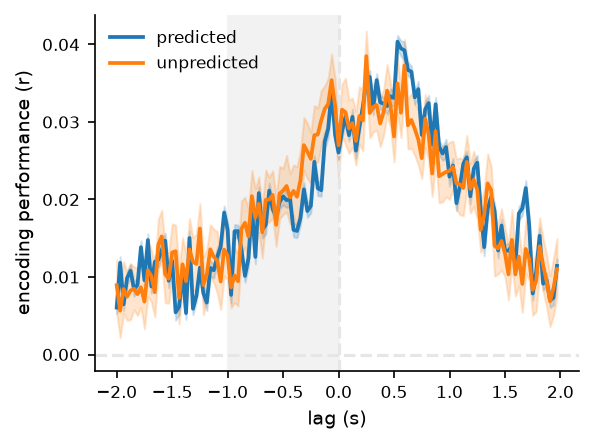

In [5]:
colors = plt.get_cmap("tab20")([0, 2])

fig, ax = plt.subplots(figsize=(4, 3), layout="tight")
ax.axvspan(-1, 0, color=(.95, .95, .95), zorder=0)
ax.axvline(0, c=(.9, .9, .9), ls="--")
ax.axhline(0, c=(.9, .9, .9), ls="--")

for label, group_scores, color in zip(["predicted", "unpredicted"], [scores_pred, scores_unpred], colors):
    mean = group_scores[:, sig_mask].mean((0, 1))
    lower, upper = np.percentile(group_scores[:, sig_mask].mean(1), [2.5, 97.5], axis=0)
    ax.fill_between(lags, lower, upper, alpha=0.2, color=color)
    ax.plot(lags, mean, color=color, label=label, lw=1.8)
    print(f"{label}: peak r = {mean.max():.3f} at {lags[mean.argmax()]:.3f} s")

ax.set_xlabel("lag (s)")
ax.set_ylabel("encoding performance (r)")
ax.legend(loc="best")
fig.savefig("../figures/prediction/sub-03-lags.svg")
plt.show()

## Before word onset

We define the pre-onset window as -1 to 0 s relative to word onset. For each electrode, we take the mean encoding performance in this window for each group and average the difference between groups over iterations.

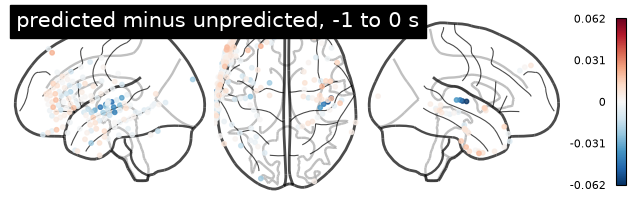

94 of 185 significant electrodes have a positive difference
The electrode-averaged difference is above 0 in 0.0% of iterations


In [6]:
window = (lags >= -1) & (lags < 0)
diff = (scores_pred[..., window].mean(-1) - scores_unpred[..., window].mean(-1)).mean(0)

values = diff[sig_mask]
vmax = np.abs(values).max()
order = values.argsort()

fig, ax = plt.subplots(figsize=(8, 2.4), dpi=100)
plot_markers(values[order], coords[sig_mask][order],
             node_size=10, display_mode="lzr",
             node_cmap="RdBu_r", colorbar=True, alpha=0.8,
             node_vmin=-vmax, node_vmax=vmax,
             title="predicted minus unpredicted, -1 to 0 s", figure=fig, axes=ax)
fig.savefig("../figures/prediction/sub-03-window-brainmap.svg")
plt.show()

window_diff = (scores_pred[:, sig_mask][..., window].mean((1, 2))
               - scores_unpred[:, sig_mask][..., window].mean((1, 2)))  # one value per iteration
print(f"{(values > 0).sum()} of {sig_mask.sum()} significant electrodes have a positive difference")
print(f"The electrode-averaged difference is above 0 in {(window_diff > 0).mean():.1%} of iterations")

These numbers describe sub-03 only and are not a statistical test. Next, we compare the difference against a null distribution that preserves the autocorrelation of the neural signal.